# Modèle 3 (essai) — Aura ou crise convulsive en voiture (Régression logistique, capteurs du siège et du volant)

**Statut : essai, à discuter avec l'encadrante.** Ce notebook ne remplace pas le modèle 2 : il sert à décider lequel garder.

**Contexte voiture :** le conducteur ne porte rien ; on n'utilise que le **PPG du volant** (rythme cardiaque) et l'**accéléromètre du siège / volant** (mouvement). Les variables de la montre (`capteur_BLE2`, `acc_moyenne`) sont retirées.

**Question posée :** pour une crise déjà repérée, est-ce une **Aura** ou une **crise convulsive** (Tonic-Clonic et Other regroupés) ?

**Pourquoi cet essai :** dans le modèle 2 (3 types), le type « Other » est mal reconnu (AUC 0,65) alors qu'Aura l'est bien (0,79). Une question à 2 classes pourrait donner une meilleure AUC.

| | |
|---|---|
| Modèle | Régression logistique (pénalité elastic-net), meilleure AUC des 8 candidats |
| Données | `donnees_fusionnees_v2/osdb_unifie_selection.csv` : les mêmes 469 crises et 51 variables (cabine) que le modèle 2 |
| Résultat officiel | AUC **0,713 ± 0,180** · exactitude équilibrée **0,616** (hasard : 0,5) |
| Le modèle 2 sur la même question | AUC **0,732** |
| Modèle 1 utilisé dans la chaîne | **One-Class SVM « une classe » v3** (force du mouvement + hausse par rapport au calme des 2 dernières minutes, chaque patient pondéré ; AUC 0,858), appris sur les seules fenêtres de crise (`Modele1_detection_crise_une_classe.ipynb`) |
| Modèle sauvegardé | `modeles_cabine/modele3_regression_logistique.joblib` (et sa version rapide `.onnx`) |

Le résultat officiel vient de `code_modeles_v2/entrainer_modele3.py --cabine` : mêmes 5 plis par patient, mêmes 8 candidats, même validation imbriquée et même mesure CPU / RAM / GPU que le modèle 2.

**Plan**
1. Charger les données
2. Résumer chaque crise et définir la cible à 2 classes
3. Définir le modèle
4. L'évaluer sur des patients jamais vus
5. Comparer au modèle 2 sur la même question
6. Matrice de confusion et courbe ROC
7. Explicabilité (XAI)
8. La chaîne complète : modèle 1 puis modèle 3
9. Ressources (CPU, RAM, GPU) et version rapide (ONNX)
10. Conclusion : que garder ?

## 0. Imports et chemins

In [ ]:
# ===== 0. CHEMINS DU PROJET : exécuter cette cellule en premier =====
# Données : lues dans le dossier partagé « AI » (AI/datasets/), en lecture seule.
# Résultats : écrits dans VOTRE Drive, dans MyDrive/AI_outputs/<NOTEBOOK>.
#
# Une seule fois par personne, dans Google Drive (navigateur) :
#   « Partagés avec moi » > clic droit sur « AI » > Organiser > Ajouter un raccourci > « Mon Drive »
import glob, os
from pathlib import Path

NOTEBOOK = "seizure_type"          # sous-dossier de sortie de ce notebook
BESOINS = ['seizure']              # datasets utilisés par ce notebook (clés de DATA ci-dessous)
AI_ROOT_MANUEL = None              # sur un PC uniquement, ex. r"G:\Mon Drive\AI" ; sinon laisser None

try:                               # Colab : monter Google Drive
    from google.colab import drive
    drive.mount("/content/drive")
    EN_COLAB = True
except ImportError:                # Jupyter sur un PC
    EN_COLAB = False


def trouver_racine_ai(nom="AI"):
    """Le dossier « AI » qui contient datasets/ et XAI/ (raccourci ou dossier dans Mon Drive, ou Drive partagé)."""
    ok = lambda p: (Path(p) / "datasets").is_dir() and (Path(p) / "XAI").is_dir()
    if AI_ROOT_MANUEL:
        return Path(AI_ROOT_MANUEL)
    for base in ("MyDrive", "Shareddrives"):
        for niveaux in range(4):                       # AI à la racine, puis jusqu'à 3 dossiers plus bas
            for p in sorted(glob.glob(f"/content/drive/{base}/{'*/' * niveaux}{nom}")):
                if ok(p):
                    return Path(p)
    for d in (Path.cwd(), *Path.cwd().parents):        # PC : notebook ouvert depuis le dossier AI synchronisé
        for p in (d, d / nom):
            if ok(p):
                return p
    raise FileNotFoundError(
        f"Dossier « {nom} » introuvable. Dans Google Drive : « Partagés avec moi » > clic droit sur « {nom} » "
        "> Organiser > Ajouter un raccourci > « Mon Drive », puis relancer cette cellule. "
        "Sur un PC : renseigner AI_ROOT_MANUEL.")


def _dossiers(racine, profondeur):
    """`racine` puis ses sous-dossiers, du moins profond au plus profond (dossiers cachés ignorés)."""
    niveau = [Path(racine)] if Path(racine).is_dir() else []
    for n in range(profondeur + 1):
        yield from niveau
        if n == profondeur:
            return
        suivant = []
        for d in niveau:
            try:
                with os.scandir(d) as entrees:
                    suivant += sorted(Path(e.path) for e in entrees
                                      if e.is_dir() and not e.name.startswith((".", "__")))
            except OSError:
                pass
        niveau = suivant


def trouver_fichier(noms, *dossiers, profondeur=3):
    """Premier fichier appelé `noms` (un nom ou une liste) dans `dossiers` ou leurs sous-dossiers."""
    noms = [noms] if isinstance(noms, str) else list(noms)
    for racine in dossiers:
        for d in _dossiers(racine, profondeur):
            for nom in noms:
                if (d / nom).is_file():
                    return d / nom
    raise FileNotFoundError(f"{' / '.join(noms)} introuvable dans : " + " ; ".join(map(str, dossiers)))


def trouver_dossier_contenant(sous_dossier, *dossiers, profondeur=3):
    """Premier dossier (dans `dossiers` ou leurs sous-dossiers) qui contient `sous_dossier`."""
    for racine in dossiers:
        for d in _dossiers(racine, profondeur):
            if (d / sous_dossier).is_dir():
                return d
    raise FileNotFoundError(f"Aucun dossier contenant {sous_dossier}/ dans : " + " ; ".join(map(str, dossiers)))


AI_ROOT = trouver_racine_ai()
DATASETS = AI_ROOT / "datasets"


def dataset(*mots, exact=False):
    """Sous-dossier de datasets/ dont le nom contient l'un des mots (ou vaut ce mot si exact=True), sans tenir compte des majuscules."""
    dossiers = sorted(d for d in DATASETS.iterdir() if d.is_dir())
    for mot in mots:
        for d in dossiers:
            if (d.name.lower() == mot.lower()) if exact else (mot.lower() in d.name.lower()):
                return d
    return DATASETS / mots[0]      # introuvable : signalé « MANQUANT » ci-dessous


DATA = {
    "seizure":     dataset("seizure"),                               # seizure dataset (release from github)
    "stroke":      dataset("neuroface", "stroke"),                   # NeuroFace Stroke dataset
    "cardiac":     dataset("heart"),                                 # heart diseasing dataset
    "cardiac_csv": dataset("cardiac_arrest_csv", "data", exact=True),  # CSV du modèle arrêt cardiaque
}

# Le dossier partagé est en lecture seule : chacun écrit ses résultats dans son propre Drive
SORTIES = (Path("/content/drive/MyDrive") if EN_COLAB else Path.cwd()) / "AI_outputs" / NOTEBOOK
SORTIES.mkdir(parents=True, exist_ok=True)

print("Dossier AI :", AI_ROOT)
for cle in BESOINS:
    print(f"  {'OK      ' if DATA[cle].is_dir() else 'MANQUANT'} DATA[{cle!r}] = {DATA[cle]}")
print("Sorties    :", SORTIES)

In [ ]:
%pip install -q shap onnxruntime   # absents de Colab par défaut (sans effet s'ils sont déjà installés)

In [ ]:
import json
import sys
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import shap
from IPython.display import Image, display
from scipy.stats import rankdata
from sklearn.base import BaseEstimator, TransformerMixin, clone
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import ConfusionMatrixDisplay, balanced_accuracy_score, recall_score, roc_auc_score, roc_curve
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

warnings.filterwarnings("ignore")

# Racine du projet : le dossier qui contient donnees_fusionnees_v2/, resultats/, modeles_cabine/, code_modeles_v2/.
# Cherché dans AI/datasets/<dossier seizure>/ (« seizure dataset (release from github) »), sinon dans AI/XAI/ (cellule 0).
PROJECT_ROOT = trouver_dossier_contenant("donnees_fusionnees_v2", DATA["seizure"], AI_ROOT / "XAI")
DONNEES = PROJECT_ROOT / "donnees_fusionnees_v2" / "osdb_unifie_selection.csv"
RESULTATS = PROJECT_ROOT / "resultats" / "osdb_modeles_cabine"
XAI = PROJECT_ROOT / "resultats" / "osdb_xai_cabine"
FIG_XAI = PROJECT_ROOT / "rapports" / "figures_xai_cabine"
MODELE_SAUVE = PROJECT_ROOT / "modeles_cabine" / "modele3_regression_logistique.joblib"
print("Projet :", PROJECT_ROOT)

## 1. Charger les données

Exactement comme pour le modèle 2 : fenêtres de 5 s, quatre variables très asymétriques passées au `log(1 + x)`, et les crises Tonic-Clonic, Other et Aura (Suspected et Unknown retirées).

In [2]:
# Version cabine : PPG du volant et accéléromètre du siège / volant
SIGNAL = ["hr", "acc_ecart_type", "acc_amplitude", "acc_puissance_mouvement",
          "acc_puissance_3_8Hz", "acc_energie_3_8Hz_pct", "acc_freq_dominante"]
LOG = ["acc_ecart_type", "acc_amplitude", "acc_puissance_mouvement", "acc_puissance_3_8Hz"]
COLONNES = ["niveau", "eventId", "userId", "type", "subType", "secondsFromEvent", "cible_pendant_crise",
            *SIGNAL]

table = pd.read_csv(DONNEES, usecols=COLONNES, dtype={"eventId": str, "userId": str})
fenetres = (table[table["niveau"] == "fenetre"]
            .sort_values(["eventId", "secondsFromEvent"])
            .reset_index(drop=True))
fenetres[LOG] = np.log1p(fenetres[LOG])
evenements = table[table["niveau"] == "evenement"].set_index("eventId")

## 2. Résumer chaque crise et définir la cible

Même résumé que le modèle 2 cabine (51 variables par crise, sans les variables de la montre). Seule la cible change :
- **0 = crise convulsive** : Tonic-Clonic ou Other ;
- **1 = Aura**.

Les plis par patient sont **les mêmes que ceux du modèle 2** (tirés pour équilibrer les 3 types), pour que la comparaison soit juste.

In [3]:
def _q10(s):
    return s.quantile(0.10)


def _q90(s):
    return s.quantile(0.90)


def resume_crise(fenetres_crise):
    """Une ligne par crise : statistiques des variables du signal sur ses fenêtres de crise."""
    par_crise = fenetres_crise.groupby("eventId", sort=True)
    resume = par_crise[SIGNAL].agg(["mean", "std", "min", "max", "median", _q10, _q90])
    resume.columns = [f"{c}_{s.lstrip('_')}" for c, s in resume.columns]
    colonnes_std = [c for c in resume.columns if c.endswith("_std")]
    resume[colonnes_std] = resume[colonnes_std].fillna(0.0)
    resume["duree_crise_s"] = par_crise.size() * 5
    premier_hr = par_crise["hr"].apply(lambda s: s.dropna().iloc[0] if s.notna().any() else np.nan)
    resume["hr_hausse"] = par_crise["hr"].max() - premier_hr
    return resume


crises = evenements[(evenements["type"] == "Seizure") & evenements["subType"].isin(["Tonic-Clonic", "Other", "Aura"])]
fenetres_crise = fenetres[(fenetres["cible_pendant_crise"] == 1) & fenetres["eventId"].isin(crises.index)]
X = resume_crise(fenetres_crise)
crises = crises.loc[X.index]
y = (crises["subType"] == "Aura").astype(int).to_numpy()  # 1 = Aura, 0 = convulsive
patients = crises["userId"].to_numpy()
CLASSES = ["convulsive", "Aura"]

print(f"X : {X.shape[0]} crises × {X.shape[1]} variables, {len(set(patients))} patients")
print("Crises par classe :", {CLASSES[k]: int(n) for k, n in enumerate(np.bincount(y))})

X : 469 crises × 51 variables, 31 patients
Crises par classe : {'convulsive': 406, 'Aura': 63}


## 3. Le modèle

Même chaîne que le modèle 2 : imputation par la médiane → standardisation → sélection par corrélation → régression logistique. Réglages retenus par la recherche (réglée sur l'AUC) :

| Réglage | Valeur | Signification |
|---|---|---|
| `C` | 40,3 | régularisation **faible** : le modèle suit beaucoup les données (voir l'explicabilité) |
| `l1_ratio` | 0,083 | surtout L2 : réduit les coefficients sans en mettre à zéro |
| seuil de sélection | 0,10 | variables gardées si leur corrélation avec la classe est au moins 0,10 |
| `class_weight` | `balanced` | les auras (63) pèsent autant que les crises convulsives (406) |

In [4]:
class SelectionCorrelation(TransformerMixin, BaseEstimator):
    """Garde les variables dont |corrélation| (max de Pearson et Spearman) avec au moins une classe >= seuil."""

    def __init__(self, seuil=0.10):
        self.seuil = seuil

    def fit(self, X, y):
        X = np.asarray(X, dtype=float)
        classes = np.unique(y)
        Y = (np.asarray(y)[:, None] == classes[None, :]).astype(float)
        if len(classes) == 2:
            Y = Y[:, 1:]
        force = np.zeros(X.shape[1])
        for A, B in ((X, Y), (rankdata(X, axis=0), rankdata(Y, axis=0))):
            A = (A - A.mean(0)) / np.where(A.std(0) > 0, A.std(0), np.inf)
            B = (B - B.mean(0)) / np.where(B.std(0) > 0, B.std(0), np.inf)
            force = np.maximum(force, np.abs(A.T @ B / len(A)).max(axis=1))
        self.correlation_ = force
        self.support_ = force >= self.seuil
        if not self.support_.any():
            self.support_[np.argmax(force)] = True
        return self

    def transform(self, X):
        return np.asarray(X, dtype=float)[:, self.support_]


modele = Pipeline([
    ("imputation", SimpleImputer(strategy="median", keep_empty_features=True)),
    ("standardisation", StandardScaler()),
    ("selection", SelectionCorrelation(seuil=0.10)),
    ("modele", LogisticRegression(C=40.3448449894972, l1_ratio=0.08311249263060239, class_weight="balanced",
                                  solver="saga", max_iter=3000)),
])
modele

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('imputation', ...), ('standardisation', ...), ...]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"strategy strategy: str or Callable, default='mean'The imputation strategy.- If ""mean"", then replace missing values using the mean along each column. Can only be used with numeric data.- If ""median"", then replace missing values using the median along each column. Can only be used with numeric data.- If ""most_frequent"", then replace missing using the most frequent value along each column. Can be used with strings or numeric data. If there is more than one such value, only the smallest is returned.- If ""constant"", then replace missing values with fill_value. Can be used with strings or numeric data.- If an instance of Callable, then replace missing values using the scalar statistic returned by running the callable over a dense 1d array containing non-missing values of each column... versionadded:: 0.20 strategy=""constant"" for fixed value imputation... versionadded:: 1.5 strategy=callable for custom value imputation.",'median'
,"keep_empty_features keep_empty_features: bool, default=FalseIf True, features that consist exclusively of missing values when`fit` is called are returned in results when `transform` is called.The imputed value is always `0` except when `strategy=""constant""`in which case `fill_value` will be used instead... versionadded:: 1.2",True
,"missing_values missing_values: int, float, str, np.nan, None or pandas.NA, default=np.nanThe placeholder for the missing values. All occurrences of`missing_values` will be imputed. For pandas' dataframes withnullable integer dtypes with missing values, `missing_values`can be set to either `np.nan` or `pd.NA`.",nan
,"fill_value fill_value: str or numerical value, default=NoneWhen strategy == ""constant"", `fill_value` is used to replace alloccurrences of missing_values. For string or object data types,`fill_value` must be a string.If `None`, `fill_value` will be 0 when imputing numericaldata and ""missing_value"" for strings or object data types.",None
,"copy copy: bool, default=TrueIf True, a copy of X will be created. If False, imputation willbe done in-place whenever possible. Note that, in the following cases,a new 

## 4. Évaluation sur des patients jamais vus

Validation croisée par patient en 5 plis. Mesures :
- **AUC** : probabilité que le modèle note une aura plus haut qu'une crise convulsive (0,5 = hasard, 1 = parfait) ;
- **exactitude équilibrée** : moyenne du rappel des deux classes (0,5 = hasard) ;
- **rappel** de chaque classe : part des crises de cette classe bien reconnues.

> Les réglages ci-dessus ont été choisis en regardant tous les patients : les chiffres d'ici seront **proches mais pas identiques** au résultat officiel (AUC 0,713), qui vient d'une validation imbriquée plus stricte.

In [5]:
# Mêmes plis que le modèle 2 : tirés sur les 3 types, puis appliqués à la cible à 2 classes
types = crises["subType"].map({"Tonic-Clonic": 0, "Other": 1, "Aura": 2}).to_numpy()
plis = list(StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=42).split(X, types, groups=patients))

proba = np.zeros(len(y))
lignes = []
for i, (train, test) in enumerate(plis, start=1):
    m = clone(modele).fit(X.iloc[train], y[train])
    proba[test] = m.predict_proba(X.iloc[test])[:, 1]
    pred = (proba[test] >= 0.5).astype(int)
    rappel_conv, rappel_aura = recall_score(y[test], pred, labels=[0, 1], average=None)
    lignes.append({"pli": i, "patients test": len(set(patients[test])), "crises test": len(test),
                   "auras test": int(y[test].sum()), "AUC": roc_auc_score(y[test], proba[test]),
                   "exactitude équilibrée": balanced_accuracy_score(y[test], pred),
                   "rappel convulsive": rappel_conv, "rappel Aura": rappel_aura})

par_pli = pd.DataFrame(lignes).set_index("pli")
resume = par_pli.drop(columns=["patients test", "crises test", "auras test"]).agg(["mean", "std"])
resume.index = ["moyenne", "écart-type"]
display(par_pli.round(3))
display(resume.round(3))

,patients test,crises test,auras test,AUC,exactitude équilibrée,rappel convulsive,rappel Aura
pli,,,,,,,
1,1,198,32,0.576,0.527,0.554,0.500
2,3,125,3,0.538,0.425,0.516,0.333
3,6,57,6,0.765,0.672,0.843,0.500
4,8,48,15,0.826,0.679,0.758,0.600
5,13,41,7,0.828,0.681,0.647,0.714


,AUC,exactitude équilibrée,rappel convulsive,rappel Aura
moyenne,0.707,0.597,0.664,0.530
écart-type,0.139,0.116,0.137,0.141


### Comparaison avec les autres candidats (résultat officiel)

Les 8 candidats, évalués avec la validation imbriquée, triés par AUC :

In [6]:
officiel = pd.read_csv(RESULTATS / "modele3_comparaison.csv", index_col="modele")
officiel[["auc_macro_moy", "auc_macro_ecart_type", "exactitude_equilibree_moy", "rappel_convulsive_moy",
          "rappel_Aura_moy"]].round(3)

,auc_macro_moy,auc_macro_ecart_type,exactitude_equilibree_moy,rappel_convulsive_moy,rappel_Aura_moy
modele,,,,,
Régression logistique,0.713,0.180,0.616,0.642,0.589
SVM (noyau RBF),0.678,0.160,0.633,0.584,0.682
Forêt aléatoire,0.576,0.103,0.529,0.706,0.352
Gradient boosting (HGB),0.572,0.135,0.537,0.770,0.304
Réseau de neurones (MLP),0.558,0.140,0.536,0.659,0.413
Extra Trees,0.556,0.138,0.536,0.720,0.353
k plus proches voisins,0.534,0.119,0.493,0.987,0.000
Référence (classe majoritaire),0.500,0.000,0.500,1.000,0.000


## 5. Comparer au modèle 2 sur la même question

Le modèle 2 sait aussi répondre « Aura ou convulsive » : il suffit d'additionner ses probabilités Tonic-Clonic et Other. On compare les deux, **pli par pli**, sur les mêmes patients :

,modèle 3 (2 classes),"modèle 2 (3 types), même question"
pli,,
1,0.410,0.595
2,0.686,0.574
3,0.824,0.840
4,0.804,0.810
5,0.840,0.840
moyenne,0.713,0.732


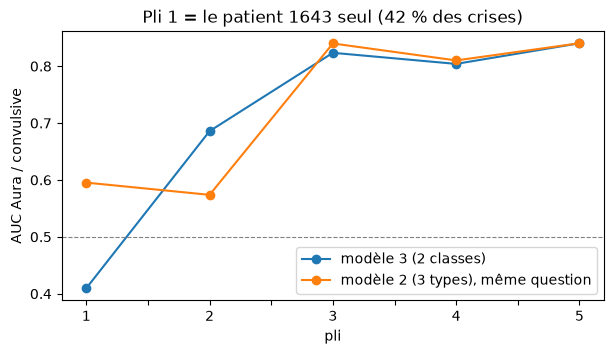

In [7]:
chaine3 = json.loads((RESULTATS / "modele3_chaine.json").read_text(encoding="utf-8"))
comparaison = pd.DataFrame({"modèle 3 (2 classes)": chaine3["auc_modele_3_plis"],
                            "modèle 2 (3 types), même question": chaine3["auc_modele_2_meme_question_plis"]},
                           index=pd.Index(range(1, 6), name="pli"))
comparaison.loc["moyenne"] = comparaison.mean()
display(comparaison.round(3))

ax = comparaison.drop(index="moyenne").plot(marker="o", figsize=(7, 3.5))
ax.axhline(0.5, color="gray", linestyle="--", linewidth=0.8)
ax.set_ylabel("AUC Aura / convulsive")
ax.set_title("Pli 1 = le patient 1643 seul (42 % des crises)")
plt.show()

**Lecture.**
- Le **modèle 2 sépare mieux** Aura et crise convulsive (0,732) que le modèle 3 entraîné exprès (0,713), dans 4 plis sur 5.
- Le modèle 3 est aussi **moins stable** : sur le patient 1643 (pli 1), son AUC tombe sous le hasard (0,410).
- Explication probable : « convulsive » mélange deux groupes différents (Tonic-Clonic et Other). Un modèle linéaire à 2 classes ne trace qu'**une** frontière ; le modèle à 3 types en trace deux et décrit mieux ces deux groupes.

## 6. Matrice de confusion et courbe ROC

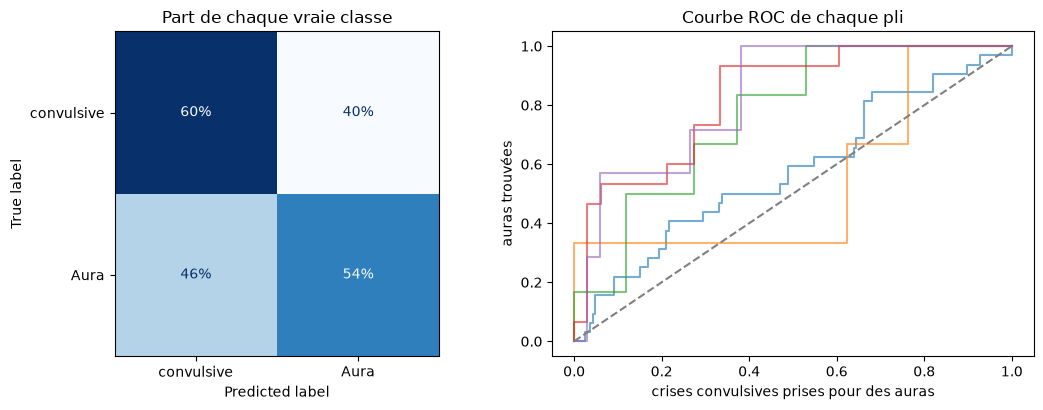

In [8]:
pred = (proba >= 0.5).astype(int)
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
ConfusionMatrixDisplay.from_predictions(y, pred, display_labels=CLASSES, normalize="true", values_format=".0%",
                                        cmap="Blues", colorbar=False, ax=axes[0])
axes[0].set_title("Part de chaque vraie classe")
for train, test in plis:
    fpr, tpr, _ = roc_curve(y[test], proba[test])
    axes[1].plot(fpr, tpr, alpha=0.6)
axes[1].plot([0, 1], [0, 1], "--", color="gray")
axes[1].set_xlabel("crises convulsives prises pour des auras")
axes[1].set_ylabel("auras trouvées")
axes[1].set_title("Courbe ROC de chaque pli")
plt.tight_layout()
plt.show()

## 7. Explicabilité (XAI)

Même démarche que pour les modèles 1 et 2 : pour une régression logistique, **SHAP linéaire** (exact) et coefficients ; pour tous les candidats, **permutation groupée** par signal sur des patients jamais vus (calculée par `code_modeles_v2/expliquer_modeles_v2.py --cabine --etape 3`).

Background dataset has 469 samples but max_samples=100. Subsampling to 100 samples for SHAP value computation. To use all samples, set max_samples=469 when initializing the masker.


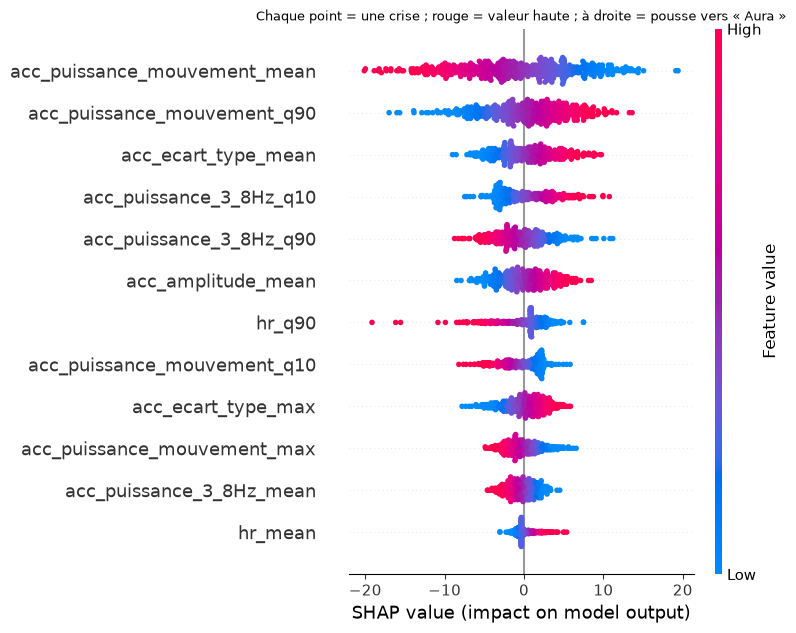

,coefficient
acc_puissance_mouvement_mean,-7.67
acc_puissance_mouvement_q90,5.19
acc_ecart_type_mean,3.69
acc_puissance_3_8Hz_q10,3.36
acc_puissance_3_8Hz_q90,-3.26
hr_q90,-3.16
acc_amplitude_mean,3.13
acc_ecart_type_max,2.42


In [9]:
final = clone(modele).fit(X, y)
gardees = X.columns[final.named_steps["selection"].support_]
preparation = Pipeline(final.steps[:-1])
Z = preparation.transform(X)
valeurs = np.asarray(shap.LinearExplainer(final.named_steps["modele"], Z).shap_values(Z))
shap.summary_plot(valeurs, Z, feature_names=list(gardees), max_display=12, show=False)
plt.title("Chaque point = une crise ; rouge = valeur haute ; à droite = pousse vers « Aura »", fontsize=9)
plt.show()

coefficients = pd.Series(final.named_steps["modele"].coef_[0], index=gardees)
coefficients.reindex(coefficients.abs().sort_values(ascending=False).index).head(8).round(2).to_frame("coefficient")

**Lecture : un signe de sur-apprentissage.** `acc_puissance_mouvement_mean` et `acc_ecart_type_mean` sont corrélées à **0,999** (elles mesurent presque la même chose), mais le modèle leur donne des effets **opposés** (-7,67 et 3,69) : il exploite de minuscules écarts entre deux jumelles, ce qui se généralise mal à un nouveau patient. Les effets se lisent mieux par signal :

groupe,amplitude acc.,durée,fréquence dominante,part 3-8 Hz,puissance 3-8 Hz,puissance mouvement,rythme cardiaque,variabilité acc.
modele,,,,,,,,
Extra Trees,-1.4,-0.5,1.3,-2.9,2.7,-1.5,7.9,-1.6
Forêt aléatoire,0.5,-0.4,-2.3,-4.1,6.7,-1.9,5.9,-1.4
Gradient boosting (HGB),-1.8,-0.2,4.0,-2.1,10.7,-0.9,2.6,-2.1
Régression logistique,9.1,0.0,-1.3,-3.2,30.7,7.4,5.2,6.9
Réseau de neurones (MLP),-4.9,-1.2,0.8,1.8,0.8,3.9,-0.0,5.0
SVM (noyau RBF),3.4,0.0,-1.5,-3.3,21.6,-0.8,8.7,3.3
k plus proches voisins,-1.9,-0.1,1.8,-3.3,6.4,-0.2,3.2,2.3


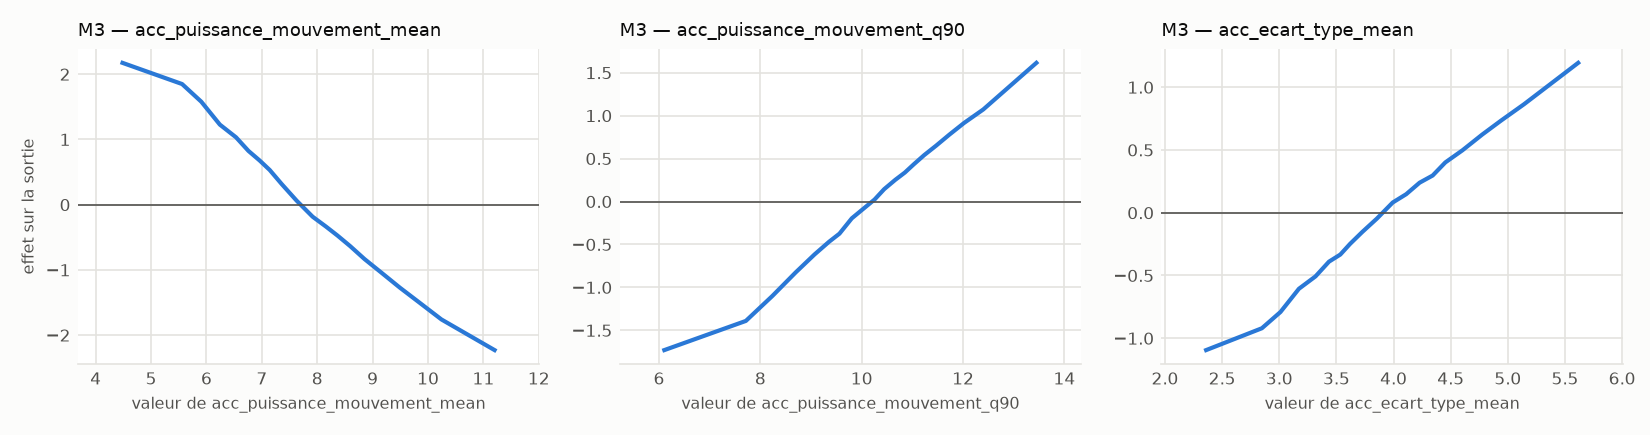

In [10]:
perm = pd.read_csv(XAI / "modele3_permutation_groupee.csv")
display(perm.pivot(index="modele", columns="groupe", values="baisse_auc_points").round(1))
display(Image(filename=str(FIG_XAI / "xai_modele3_ale.png"), width=900))

**Lecture.** Pour la régression logistique, le signal clé est **puissance 3-8 Hz** (mélanger ce signal fait perdre 30,7 points d'AUC), puis **amplitude acc.** (9,1). Une aura bouge peu en rythme et fait moins monter le cœur.

## 8. La chaîne complète : modèle 1 puis modèle 3

Comme pour le modèle 2 : le **modèle 1 « une classe » v3** (One-Class SVM appris sur les seules fenêtres de crise, avec la hausse du mouvement par rapport au calme des 2 dernières minutes et une pondération par patient) repère les fenêtres de crise de patients jamais vus, le modèle 3 résume ces fenêtres et répond « Aura » ou « convulsive ». Le modèle 3 lui-même ne change pas ; seule la chaîne est refaite (`code_modeles_v2/chaine_une_classe.py --cabine`). L'ancien modèle 1 (Extra Trees, deux classes) est gardé pour comparer.

In [11]:
chaine = json.loads((RESULTATS / "chaine_modele1_une_classe.json").read_text(encoding="utf-8"))
lignes = {}
for nom, r in chaine.items():
    lignes[nom] = {"modèle 1 : exactitude équilibrée (fenêtres)": r["modele_1_fenetres"]["exactitude_equilibree"],
                   **{k: v for k, v in r["chaine_modele_3"].items() if k != "crises"}}
pd.DataFrame(lignes).round(3)

,ancien : Extra Trees (deux classes),nouveau : One-Class SVM (une classe)
modèle 1 : exactitude équilibrée (fenêtres),0.796,0.785
crises_detectees_pct,99.800,99.600
auc_chaine_moy_plis,0.695,0.691
exactitude_equilibree_chaine,0.573,0.574
rappel_chaine_convulsive,0.559,0.530
rappel_chaine_Aura,0.587,0.619


**Lecture :**
- **99,6 %** des crises repérées avec le modèle 1 une classe v3 (ancien : 99,8 %).
- Exactitude équilibrée de la chaîne : **0,574**, comme avec l'ancien modèle 1 (0,573 ; hasard 0,5).
- AUC de la chaîne : **0,691**, contre 0,695 avant : pareil. Le modèle 1 v3 trouve plus de crises fenêtre par fenêtre sans changer le typage.

## 9. Ressources (CPU, RAM, GPU)

Mesurées comme pour les autres modèles (processus séparé, entraînement et inférence) :

In [12]:
ressources = pd.read_csv(RESULTATS / "ressources.csv")
ressources[ressources["etape"] == 3].set_index("modele")[
    ["entrainement_duree_s", "entrainement_cpu_coeurs_moy", "entrainement_ram_pic_ajout_mo",
     "entrainement_gpu_util_max_pct", "inference_lot_us_par_ligne", "inference_une_ligne_latence_ms",
     "taille_modele_ko"]].round(2)

,entrainement_duree_s,entrainement_cpu_coeurs_moy,entrainement_ram_pic_ajout_mo,entrainement_gpu_util_max_pct,inference_lot_us_par_ligne,inference_une_ligne_latence_ms,taille_modele_ko
modele,,,,,,,
Référence (classe majoritaire),0.01,0.98,2.3,0.0,3.09,1.19,5.0
Régression logistique,0.42,1.02,2.2,0.0,3.29,1.35,5.5
k plus proches voisins,0.01,1.02,2.7,0.0,7.75,1.51,162.8
SVM (noyau RBF),0.02,1.00,3.5,0.0,32.71,1.97,76.9
Forêt aléatoire,0.83,0.99,4.4,0.0,34.17,11.22,920.0
Extra Trees,0.51,1.04,8.1,0.0,42.82,12.78,2575.9
Gradient boosting (HGB),2.29,1.03,3.8,0.0,32.87,4.60,535.2
Réseau de neurones (MLP),0.06,1.00,3.1,0.0,4.35,2.05,52.5


### Version rapide pour le temps réel (ONNX)

Avec scikit-learn, prédire **une seule crise** coûte plusieurs millisecondes, bien plus que le temps moyen par ligne en lot : chaque appel paie des coûts fixes (vérification des données, tableau pandas). Le même modèle, converti au format **ONNX** par `code_modeles_v2/inference_rapide.py --cabine`, est exécuté par un moteur compilé. On vérifie qu'il donne les mêmes réponses et on compare les temps :

In [13]:
import time

import joblib

sys.path.insert(0, str(PROJECT_ROOT / "code_modeles_v2"))
from inference_rapide import ModeleRapide

modele_scikit = joblib.load(PROJECT_ROOT / "modeles_cabine" / "modele3_regression_logistique.joblib")
rapide = ModeleRapide(PROJECT_ROOT / "modeles_cabine" / "modele3_regression_logistique")
X_num = X.to_numpy(dtype=float)

identiques = np.mean(modele_scikit.predict(X) == rapide.predict(X_num))
ecart = np.abs(modele_scikit.predict_proba(X) - rapide.predict_proba(X_num)).max()
print(f"Décisions identiques : {100 * identiques:.1f} % ; écart maximal des probabilités : {ecart:.1e}")


def temps_ms(predire, n=300):
    debut = time.perf_counter()
    for i in range(n):
        predire(i % len(X))
    return 1000 * (time.perf_counter() - debut) / n


print(f"Une crise, scikit-learn : {temps_ms(lambda i: modele_scikit.predict(X.iloc[[i]])):.2f} ms")
print(f"Une crise, ONNX         : {temps_ms(lambda i: rapide.predict(X_num[i:i + 1])):.3f} ms")

Décisions identiques : 100.0 % ; écart maximal des probabilités : 7.4e-07


Une crise, scikit-learn : 1.96 ms
Une crise, ONNX         : 0.034 ms


### Mesure dans ce notebook

On mesure ici, **dans ce notebook**, ce que coûte le modèle (régression logistique, 469 crises) :

| Phase | Ce qui est mesuré |
|---|---|
| entraînement | apprendre le modèle sur toutes les lignes |
| prédiction en lot | prédire toutes les lignes d'un coup |
| une ligne (scikit-learn) | prédire une seule crise, comme en temps réel |
| une ligne (ONNX) | la même chose avec la version rapide |

Colonnes du tableau :
- `duree_ms` : temps d'une exécution (millisecondes) ; `par_ligne_us` : temps par ligne en lot (microsecondes) ;
- `cpu_coeurs_moy` : nombre moyen de cœurs du processeur occupés ; `cpu_pct_machine` : la même chose en % de la machine ;
- `ram_pic_ajout_mo` : mémoire **ajoutée** pendant le calcul (Mo) ; `ram_pic_processus_mo` : mémoire totale du notebook ;
- `gpu_util_max_pct`, `gpu_memoire_max_mo` : utilisation et mémoire de la carte graphique par ce notebook.

Chaque phase est répétée jusqu'à durer au moins 3 s (1 s pour une ligne), pour une mesure stable. La cellule prend environ une minute.

In [14]:
sys.path.insert(0, str(PROJECT_ROOT / "code_modeles_v2"))
from mesure_ressources import interpreter, mesurer_dans_le_notebook

mesures = mesurer_dans_le_notebook(modele, X, y, onnx_base=PROJECT_ROOT / "modeles_cabine" / "modele3_regression_logistique")
display(mesures.round(3))
print("Interprétation :")
for phrase in interpreter(mesures, intervalle_s=5):
    print("-", phrase)

,duree_ms,par_ligne_us,cpu_coeurs_moy,cpu_pct_machine,ram_pic_ajout_mo,ram_pic_processus_mo,gpu_util_max_pct,gpu_memoire_max_mo,repetitions
entraînement,466.160,NaN,0.96,12.0,0.1,271.9,0.0,0.0,7
prédiction en lot (toutes les lignes),1.816,3.872,1.01,12.6,0.1,272.0,0.0,0.0,1653
une ligne (scikit-learn),1.417,NaN,1.05,13.1,0.0,272.4,0.0,0.0,706
une ligne (ONNX),0.030,NaN,1.0,12.5,0.0,272.4,0.0,0.0,32869


Interprétation :
- Entraînement : 0.47 s, 1.0 cœur(s) occupé(s) en moyenne sur 8 (12 % de la machine). Un seul cœur travaille : le modèle est trop petit pour gagner à paralléliser.
- RAM : au plus +0 Mo pendant le calcul, verdict faible : tiendrait sans problème sur un téléphone.
- Prédiction en lot : 3.9 µs par ligne.
- Une ligne à la fois (temps réel) : 1.42 ms avec scikit-learn, soit 0.028 % du temps disponible entre deux lignes (5 s) ; 0.030 ms avec ONNX, 47 fois plus vite, pour les mêmes décisions. Le temps réel est largement tenu.
- GPU : 0 % (ou presque). C'est normal : scikit-learn et ONNX Runtime (version CPU) ne calculent que sur le processeur, et ce PC n'a qu'un GPU intégré. Le modèle est si petit que copier les données vers un GPU coûterait plus que le calcul gagné.


**Interprétation générale** (les chiffres exacts varient d'une exécution à l'autre, selon la charge du portable ; les ordres de grandeur restent) :
- **CPU** : le modèle tient sur **un seul cœur** pour les petits calculs ; le modèle 1 (One-Class SVM, une classe) aussi : moins d'une seconde d'entraînement sur un cœur.
- **RAM** : quelques Mo au plus. Les modèles sont légers : ils tiendraient sur un téléphone.
- **GPU : 0 %**, et c'est normal. scikit-learn et ONNX Runtime (version CPU) ne calculent que sur le processeur, et ce PC n'a qu'un GPU intégré Intel. Avec si peu de données, copier les données vers un GPU coûterait plus que le calcul gagné : le GPU n'apporterait rien ici.
- **Temps réel** : même avec scikit-learn, prédire une ligne prend quelques millisecondes, une infime partie des 5 s entre deux fenêtres. Avec ONNX, c'est encore 50 à 250 fois plus rapide, pour les mêmes décisions : utile sur une montre ou un téléphone, plus lents et sur batterie.

## 10. Conclusion : que garder ?

| | Modèle 2 (3 types) | Modèle 3 (Aura / convulsive) |
|---|---|---|
| Question | Tonic-Clonic, Other ou Aura | Aura ou convulsive |
| AUC sur sa propre question | 0,701 | 0,713 |
| AUC sur « Aura ou convulsive » | **0,732** | 0,713 |
| Stabilité (écart-type de l'AUC entre plis) | 0,089 | 0,180 |
| Pli du patient 1643 (AUC Aura / convulsive) | 0,595 | 0,410 |
| Chaîne avec le modèle 1 une classe v3 (exactitude équilibrée) | 0,374 (3 types, hasard 0,333 ; ancien modèle 1 : 0,375) | 0,574 (2 classes, hasard 0,5 ; ancien : 0,573) |
| Ressources | quelques Ko, quelques µs par crise, CPU seul | pareil |

**Recommandation : garder le modèle 2.** Même pour la question simplifiée « Aura ou convulsive », il fait mieux (AUC 0,732 contre 0,713) et il est plus stable. Si l'on n'a besoin que de « Aura ou convulsive », il suffit d'utiliser sa probabilité d'aura : pas besoin d'un modèle de plus.

Le modèle 3 reste utile comme **essai documenté** : il montre que regrouper Tonic-Clonic et Other n'aide pas, et que la limite vient des données (peu de patients, un patient dominant, un seul capteur), pas de la façon de poser la question.